Name: **Sufyan Afzal**

Reg No: **FA23-BAI-061**

# Lab Assignment 2 - ANN & DL

### Task 1

Cell 2 — Import libraries and set random seeds

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully.")

TensorFlow version: 2.19.1
NumPy version: 1.26.4
Libraries imported successfully.


Cell 3 — Load the Iris dataset

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

df = X.copy()
df["species"] = [iris.target_names[i] for i in y]

print("Dataset shape:", df.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))
print("Species:", list(iris.target_names))
print("\nFirst five rows:")
display(df.head())
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)
Number of features: 4
Number of classes: 3
Species: ['setosa', 'versicolor', 'virginica']

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Missing values: 0

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Cell 4 — Visualize the dataset

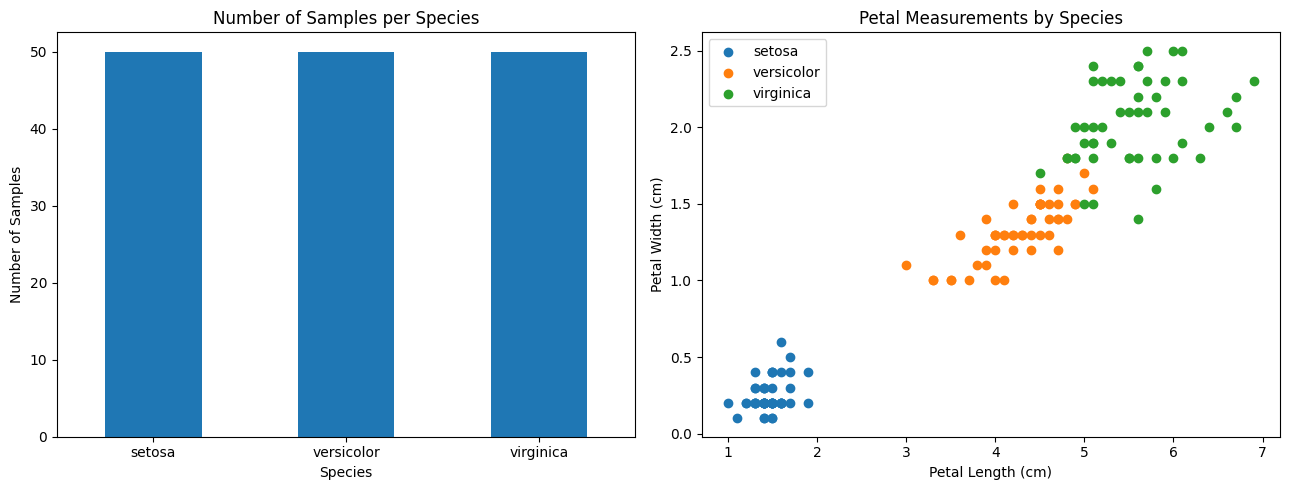

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df["species"].value_counts().reindex(iris.target_names).plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Number of Samples per Species")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Number of Samples")
axes[0].tick_params(axis="x", rotation=0)

for species in iris.target_names:
    subset = df[df["species"] == species]
    axes[1].scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=species
    )

axes[1].set_title("Petal Measurements by Species")
axes[1].set_xlabel("Petal Length (cm)")
axes[1].set_ylabel("Petal Width (cm)")
axes[1].legend()

plt.tight_layout()
plt.show()

Cell 5 — Split into training, validation and testing sets

In [4]:
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Samples": [len(y_train), len(y_val), len(y_test)],
    "Percentage": [
        len(y_train) / len(y) * 100,
        len(y_val) / len(y) * 100,
        len(y_test) / len(y) * 100
    ]
})

display(split_summary)

print("Training class counts:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))
print("Testing class counts:", np.bincount(y_test))

,Dataset,Samples,Percentage
0,Training,90,60.0
1,Validation,30,20.0
2,Testing,30,20.0


Training class counts: [30 30 30]
Validation class counts: [10 10 10]
Testing class counts: [10 10 10]


Cell 6 — Preprocess the data

,Feature,Training Mean,Training Standard Deviation
0,sepal length (cm),-0.0,1.0
1,sepal width (cm),-0.0,1.0
2,petal length (cm),0.0,1.0
3,petal width (cm),-0.0,1.0


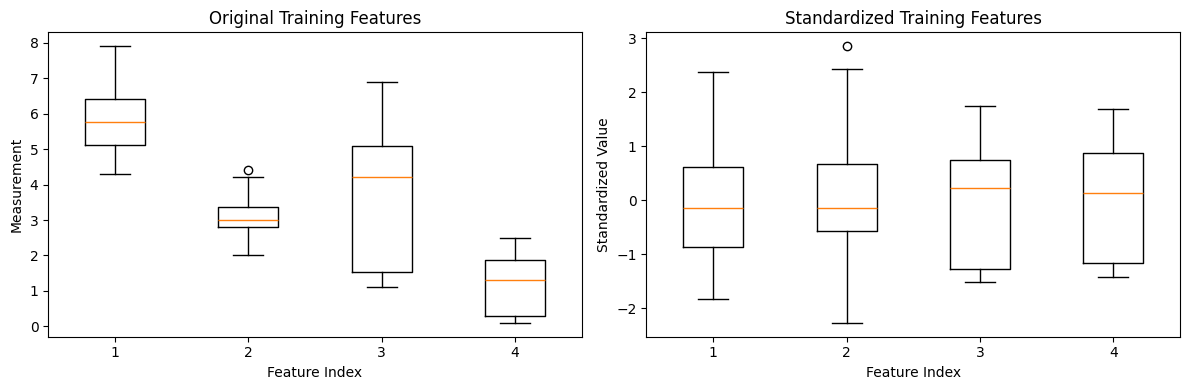

Training shape: (90, 4)
Validation shape: (30, 4)
Testing shape: (30, 4)
Preprocessing completed.


In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

scaled_summary = pd.DataFrame({
    "Feature": iris.feature_names,
    "Training Mean": X_train.mean(axis=0),
    "Training Standard Deviation": X_train.std(axis=0)
})

display(scaled_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(X_train_raw.values)
axes[0].set_title("Original Training Features")
axes[0].set_xlabel("Feature Index")
axes[0].set_ylabel("Measurement")

axes[1].boxplot(X_train)
axes[1].set_title("Standardized Training Features")
axes[1].set_xlabel("Feature Index")
axes[1].set_ylabel("Standardized Value")

plt.tight_layout()
plt.show()

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)
print("Preprocessing completed.")

Cell 7 — Build the MLP model and training function

In [6]:
def build_model(initializer="he_normal", regularization=None, dropout_rate=0.0):
    tf.keras.backend.clear_session()

    if regularization == "l1":
        regularizer = l1(0.001)
    elif regularization == "l2":
        regularizer = l2(0.001)
    else:
        regularizer = None

    model = Sequential([
        tf.keras.Input(shape=(X_train.shape[1],)),
        Dense(16, activation="relu", kernel_initializer=initializer, kernel_regularizer=regularizer),
        Dropout(dropout_rate),
        Dense(8, activation="relu", kernel_initializer=initializer, kernel_regularizer=regularizer),
        Dense(3, activation="softmax", kernel_initializer=initializer)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


class LearningRateRecorder(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.rates = []

    def on_epoch_begin(self, epoch, logs=None):
        self.rates.append(float(tf.keras.backend.get_value(self.model.optimizer.learning_rate)))


def train_model(initializer="he_normal", regularization=None, dropout_rate=0.0,
                learning_rate_strategy="constant", batch_size=16, epochs=5,
                early_stopping=False):
    model = build_model(initializer, regularization, dropout_rate)
    callbacks = []

    if learning_rate_strategy == "exponential":
        callbacks.append(
            LearningRateScheduler(lambda epoch, lr: 0.01 * (0.8 ** epoch))
        )

    lr_recorder = LearningRateRecorder()
    callbacks.append(lr_recorder)

    if early_stopping:
        callbacks.append(
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        )

    start = time.perf_counter()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=0
    )

    elapsed = time.perf_counter() - start

    results = {
        "model": model,
        "history": history,
        "learning_rates": lr_recorder.rates,
        "training_time": elapsed,
        "epochs_completed": len(history.history["loss"])
    }

    return results


print("MLP model and training function are ready.")
print("Input neurons:", X_train.shape[1])
print("Hidden layer neurons: 16 and 8")
print("Output neurons:", len(iris.target_names))

MLP model and training function are ready.
Input neurons: 4
Hidden layer neurons: 16 and 8
Output neurons: 3


Cell 8 — Requirement 2: Compare weight initialization

,Initialization,Epochs,Final Training Accuracy,Final Validation Accuracy,Final Training Loss,Final Validation Loss,Training Time (seconds)
0,he_normal,5,0.9111,0.8333,0.4871,0.4831,1.6318
1,glorot_uniform,5,0.9556,0.9333,0.5172,0.5157,1.3550


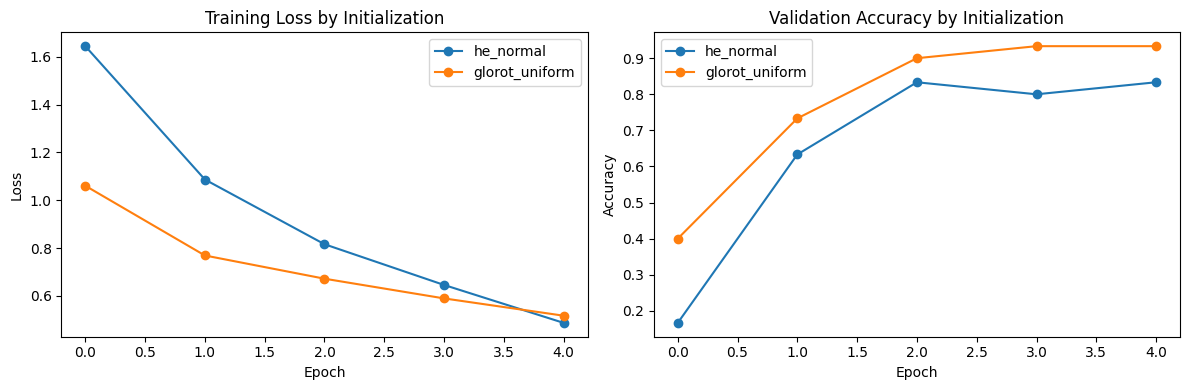

He initialization is designed for ReLU activations.
Glorot initialization balances the variance across layers.
The table and plots show the observed results for this run.


In [7]:
initialization_results = {}

for initializer in ["he_normal", "glorot_uniform"]:
    initialization_results[initializer] = train_model(
        initializer=initializer,
        batch_size=16,
        epochs=5
    )

initialization_table = []

for name, result in initialization_results.items():
    history = result["history"].history

    initialization_table.append({
        "Initialization": name,
        "Epochs": result["epochs_completed"],
        "Final Training Accuracy": history["accuracy"][-1],
        "Final Validation Accuracy": history["val_accuracy"][-1],
        "Final Training Loss": history["loss"][-1],
        "Final Validation Loss": history["val_loss"][-1],
        "Training Time (seconds)": result["training_time"]
    })

initialization_df = pd.DataFrame(initialization_table)
display(initialization_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, result in initialization_results.items():
    h = result["history"].history
    axes[0].plot(h["loss"], marker="o", label=name)
    axes[1].plot(h["val_accuracy"], marker="o", label=name)

axes[0].set_title("Training Loss by Initialization")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Validation Accuracy by Initialization")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[0].legend()
axes[1].legend()

plt.tight_layout()
plt.show()

print("He initialization is designed for ReLU activations.")
print("Glorot initialization balances the variance across layers.")
print("The table and plots show the observed results for this run.")

Cell 9 — Requirement 3: Compare learning-rate strategies

,Strategy,Initial Learning Rate,Final Learning Rate,Final Training Loss,Final Validation Loss,Final Validation Accuracy,Training Time (seconds)
0,constant,0.01,0.0100,0.0797,0.2065,0.9,3.0671
1,exponential,0.01,0.0001,0.2883,0.3952,0.8,2.7620


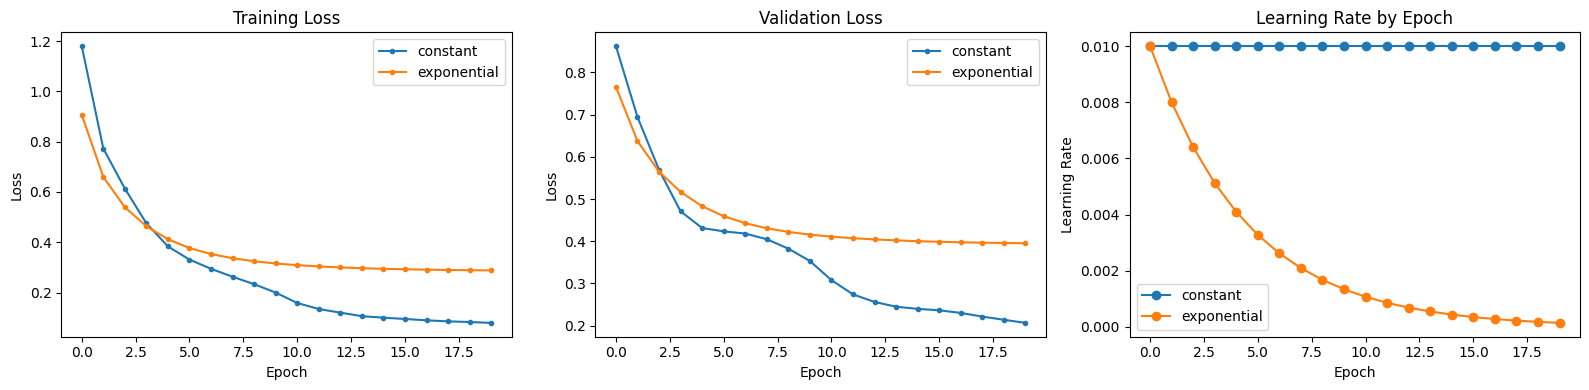

Constant learning rate: the learning rate remains unchanged.
Exponential schedule: the learning rate decreases after each epoch.
Compare validation loss and accuracy to judge which strategy worked better.


In [8]:
lr_results = {}

for strategy in ["constant", "exponential"]:
    lr_results[strategy] = train_model(
        initializer="he_normal",
        learning_rate_strategy=strategy,
        batch_size=16,
        epochs=20
    )

lr_table = []

for strategy, result in lr_results.items():
    h = result["history"].history

    lr_table.append({
        "Strategy": strategy,
        "Initial Learning Rate": result["learning_rates"][0],
        "Final Learning Rate": result["learning_rates"][-1],
        "Final Training Loss": h["loss"][-1],
        "Final Validation Loss": h["val_loss"][-1],
        "Final Validation Accuracy": h["val_accuracy"][-1],
        "Training Time (seconds)": result["training_time"]
    })

display(pd.DataFrame(lr_table).round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for strategy, result in lr_results.items():
    h = result["history"].history
    axes[0].plot(h["loss"], marker=".", label=strategy)
    axes[1].plot(h["val_loss"], marker=".", label=strategy)
    axes[2].plot(result["learning_rates"], marker="o", label=strategy)

axes[0].set_title("Training Loss")
axes[1].set_title("Validation Loss")
axes[2].set_title("Learning Rate by Epoch")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()

axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Loss")
axes[2].set_ylabel("Learning Rate")

plt.tight_layout()
plt.show()

print("Constant learning rate: the learning rate remains unchanged.")
print("Exponential schedule: the learning rate decreases after each epoch.")
print("Compare validation loss and accuracy to judge which strategy worked better.")

Cell 10 — Requirement 4: Compare batch sizes and epoch limits

,Experiment,Epochs Completed,Final Training Accuracy,Final Validation Accuracy,Final Training Loss,Final Validation Loss,Training Time (seconds)
0,"Batch 8, Epochs 5",5,0.8889,0.7667,0.3030,0.3364,1.5413
1,"Batch 8, Epochs 20",20,1.0000,0.9333,0.0338,0.3005,2.9703
2,"Batch 32, Epochs 5",5,0.8556,0.9000,0.3394,0.3430,1.3743
3,"Batch 32, Epochs 20",20,0.9000,0.8333,0.2352,0.3974,2.6682


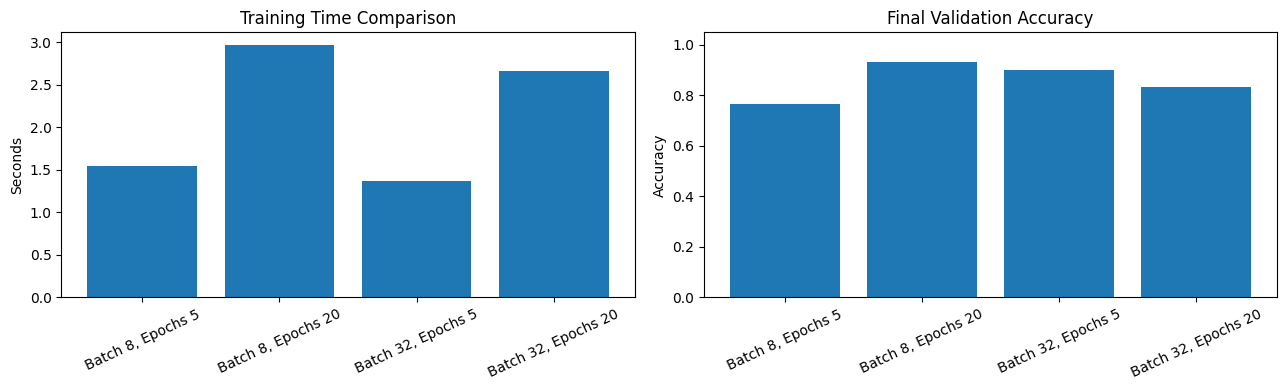

Compare the measured training times and validation accuracy.
More epochs allow more training, but do not guarantee better generalization.
Training time depends on the hardware and the number of weight updates.


In [9]:
batch_epoch_results = {}

for batch_size in [8, 32]:
    for epochs in [5, 20]:
        key = f"Batch {batch_size}, Epochs {epochs}"

        batch_epoch_results[key] = train_model(
            initializer="he_normal",
            batch_size=batch_size,
            epochs=epochs
        )

batch_epoch_table = []

for key, result in batch_epoch_results.items():
    h = result["history"].history

    batch_epoch_table.append({
        "Experiment": key,
        "Epochs Completed": result["epochs_completed"],
        "Final Training Accuracy": h["accuracy"][-1],
        "Final Validation Accuracy": h["val_accuracy"][-1],
        "Final Training Loss": h["loss"][-1],
        "Final Validation Loss": h["val_loss"][-1],
        "Training Time (seconds)": result["training_time"]
    })

batch_epoch_df = pd.DataFrame(batch_epoch_table)
display(batch_epoch_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(batch_epoch_df["Experiment"], batch_epoch_df["Training Time (seconds)"])
axes[0].set_title("Training Time Comparison")
axes[0].set_ylabel("Seconds")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(batch_epoch_df["Experiment"], batch_epoch_df["Final Validation Accuracy"])
axes[1].set_title("Final Validation Accuracy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

print("Compare the measured training times and validation accuracy.")
print("More epochs allow more training, but do not guarantee better generalization.")
print("Training time depends on the hardware and the number of weight updates.")

Cell 11 — Requirement 5: Investigate regularization and dropout

,Model,Epochs Completed,Best Epoch,Best Validation Loss,Validation Accuracy at Best Epoch,Restored Model Validation Loss,Restored Model Validation Accuracy,Training Time (seconds)
0,Baseline,45,40,0.0790,0.9333,0.0790,0.9333,5.9079
1,L1,30,25,0.2061,0.9333,0.2061,0.9333,4.6802
2,L2,50,50,0.1946,0.9333,0.1946,0.9333,6.8431
3,Dropout,44,39,0.1805,0.9333,0.1805,0.9333,6.3358


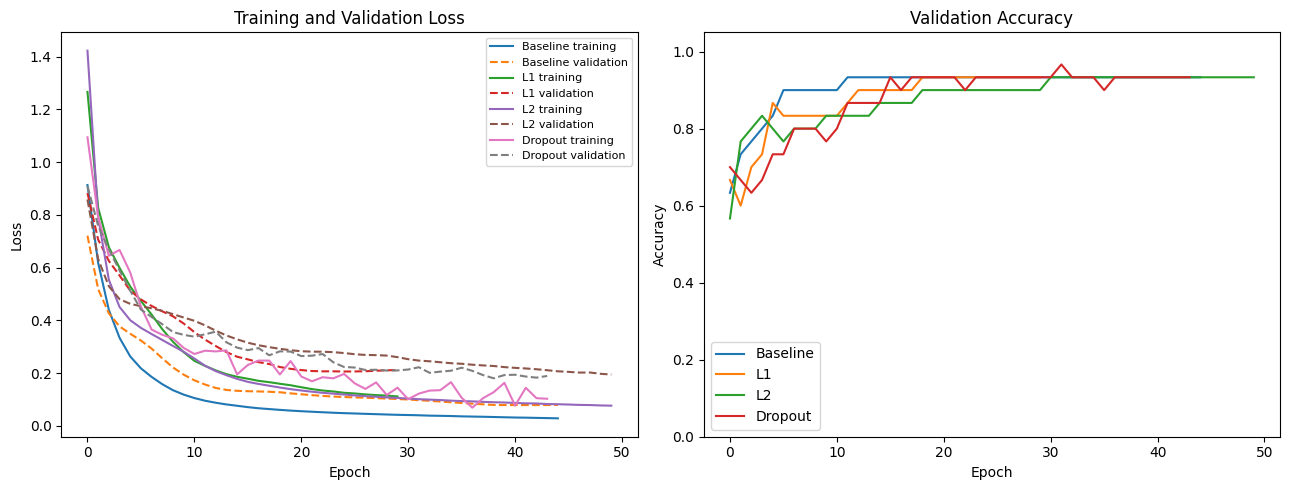

Early stopping monitors validation loss and restores the best weights.
Best epoch is the epoch with the lowest recorded validation loss.


In [13]:
regularization_results = {}

for name, config in regularization_configs.items():
    regularization_results[name] = train_model(
        initializer="he_normal",
        regularization=config["regularization"],
        dropout_rate=config["dropout_rate"],
        batch_size=16,
        epochs=50,
        early_stopping=True
    )

regularization_table = []

for name, result in regularization_results.items():
    h = result["history"].history
    best_index = int(np.argmin(h["val_loss"]))

    val_loss, val_accuracy = result["model"].evaluate(X_val, y_val, verbose=0)

    regularization_table.append({
        "Model": name,
        "Epochs Completed": result["epochs_completed"],
        "Best Epoch": best_index + 1,
        "Best Validation Loss": h["val_loss"][best_index],
        "Validation Accuracy at Best Epoch": h["val_accuracy"][best_index],
        "Restored Model Validation Loss": val_loss,
        "Restored Model Validation Accuracy": val_accuracy,
        "Training Time (seconds)": result["training_time"]
    })

regularization_df = pd.DataFrame(regularization_table)
display(regularization_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, result in regularization_results.items():
    h = result["history"].history
    axes[0].plot(h["loss"], label=f"{name} training")
    axes[0].plot(h["val_loss"], linestyle="--", label=f"{name} validation")
    axes[1].plot(h["val_accuracy"], label=name)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[1].legend()

plt.tight_layout()
plt.show()

print("Early stopping monitors validation loss and restores the best weights.")
print("Best epoch is the epoch with the lowest recorded validation loss.")

Cell 12 — Requirement 6: Analyze learning curves and select a model

Selected model: Baseline
Test loss: 0.1553
Test accuracy: 0.9333

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



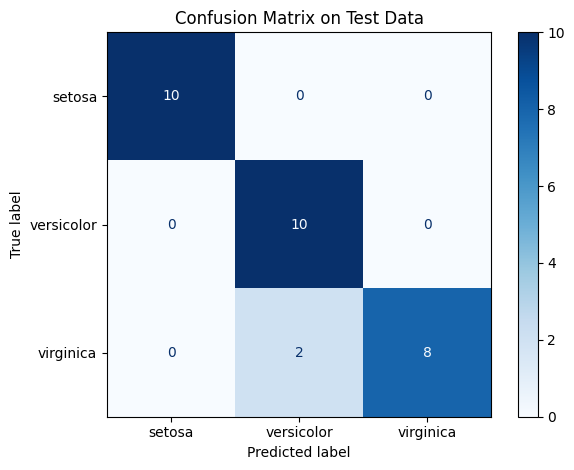

In [14]:
best_name = regularization_df.sort_values("Best Validation Loss").iloc[0]["Model"]
best_result = regularization_results[best_name]
best_model = best_result["model"]

test_loss, test_accuracy = best_model.evaluate(X_test, y_test, verbose=0)
y_prob = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Selected model:", best_name)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix on Test Data")
plt.tight_layout()
plt.show()

Cell 13 — Final results and observations

In [15]:
final_analysis = []

for name, result in regularization_results.items():
    h = result["history"].history
    best_index = int(np.argmin(h["val_loss"]))

    train_accuracy = h["accuracy"][best_index]
    val_accuracy = h["val_accuracy"][best_index]
    accuracy_gap = train_accuracy - val_accuracy

    if train_accuracy < 0.75 and val_accuracy < 0.75:
        interpretation = "Possible underfitting"
    elif accuracy_gap > 0.15:
        interpretation = "Possible overfitting"
    else:
        interpretation = "Potentially reasonable fit"

    final_analysis.append({
        "Model": name,
        "Best Epoch": best_index + 1,
        "Training Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Accuracy Gap": accuracy_gap,
        "Interpretation": interpretation
    })

final_analysis_df = pd.DataFrame(final_analysis)
display(final_analysis_df.round(4))

best_name = regularization_df.sort_values("Best Validation Loss").iloc[0]["Model"]
best_model = regularization_results[best_name]["model"]

test_loss, test_accuracy = best_model.evaluate(X_test, y_test, verbose=0)

print("Selected model:", best_name)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))
print("Final evaluation used the held-out test set.")

,Model,Best Epoch,Training Accuracy,Validation Accuracy,Accuracy Gap,Interpretation
0,Baseline,40,0.9889,0.9333,0.0556,Potentially reasonable fit
1,L1,25,0.9778,0.9333,0.0444,Potentially reasonable fit
2,L2,50,0.9889,0.9333,0.0556,Potentially reasonable fit
3,Dropout,39,0.9444,0.9333,0.0111,Potentially reasonable fit


Selected model: Baseline
Test loss: 0.1553
Test accuracy: 0.9333
Final evaluation used the held-out test set.


### Task 2: Adaline and Madaline Networks

##### Part A — Adaline

Cell 1 — Import libraries

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

print("NumPy version:", np.__version__)
print("Libraries imported successfully.")

NumPy version: 1.26.4
Libraries imported successfully.


Cell 2 — Create the bipolar AND dataset

In [17]:
X_and = np.array([
    [-1, -1],
    [-1, 1],
    [1, -1],
    [1, 1]
], dtype=float)

y_and = np.array([-1, -1, -1, 1], dtype=float)

and_table = pd.DataFrame(X_and, columns=["Input 1", "Input 2"])
and_table["Target"] = y_and.astype(int)

display(and_table)

print("Input shape:", X_and.shape)
print("Target shape:", y_and.shape)
print("Target values:", np.unique(y_and))

,Input 1,Input 2,Target
0,-1.0,-1.0,-1
1,-1.0,1.0,-1
2,1.0,-1.0,-1
3,1.0,1.0,1


Input shape: (4, 2)
Target shape: (4,)
Target values: [-1.  1.]


Cell 3 — Visualize the AND truth table

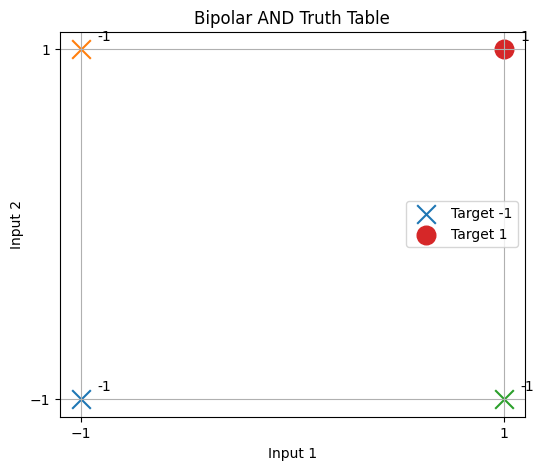

In [18]:
plt.figure(figsize=(6, 5))

for i, target in enumerate(y_and):
    plt.scatter(
        X_and[i, 0],
        X_and[i, 1],
        s=180,
        marker="o" if target == 1 else "x",
        label=f"Target {int(target)}" if int(target) not in [
            int(v) for v in y_and[:i]
        ] else None
    )
    plt.text(X_and[i, 0] + 0.08, X_and[i, 1] + 0.05, str(int(target)))

plt.title("Bipolar AND Truth Table")
plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.xticks([-1, 1])
plt.yticks([-1, 1])
plt.grid(True)
plt.legend()
plt.show()

Cell 4 — Implement Adaline using the LMS rule

In [19]:
def fit_adaline(X, y, learning_rate=0.1, epochs=1000):
    weights = np.zeros(X.shape[1])
    bias = 0.0
    mse_history = []

    for epoch in range(epochs):
        net = X @ weights + bias
        errors = y - net

        weights += learning_rate * (X.T @ errors) / len(X)
        bias += learning_rate * np.mean(errors)

        updated_net = X @ weights + bias
        mse_history.append(np.mean((y - updated_net) ** 2))

    return weights, bias, mse_history


def bipolar_predict(net):
    return np.where(net >= 0, 1, -1)


print("Adaline implementation is ready.")
print("Training rule: LMS / delta rule")
print("Training loss: Mean Squared Error")
print("Prediction threshold: net input >= 0 gives +1; otherwise -1")

Adaline implementation is ready.
Training rule: LMS / delta rule
Training loss: Mean Squared Error
Prediction threshold: net input >= 0 gives +1; otherwise -1


Cell 5 — Train Adaline on AND

In [20]:
and_weights, and_bias, and_mse = fit_adaline(
    X_and, y_and, learning_rate=0.1, epochs=1000
)

and_net = X_and @ and_weights + and_bias
and_predictions = bipolar_predict(and_net)

and_results = pd.DataFrame({
    "Input 1": X_and[:, 0].astype(int),
    "Input 2": X_and[:, 1].astype(int),
    "Target": y_and.astype(int),
    "Net Input": and_net,
    "Prediction": and_predictions
})

display(and_results.round(4))

print("Learned weights:", np.round(and_weights, 4))
print("Learned bias:", round(and_bias, 4))
print("Training accuracy:", round(np.mean(and_predictions == y_and) * 100, 2), "%")

,Input 1,Input 2,Target,Net Input,Prediction
0,-1,-1,-1,-1.5,-1
1,-1,1,-1,-0.5,-1
2,1,-1,-1,-0.5,-1
3,1,1,1,0.5,1


Learned weights: [0.5 0.5]
Learned bias: -0.5
Training accuracy: 100.0 %


Cell 6 — Plot MSE by epoch

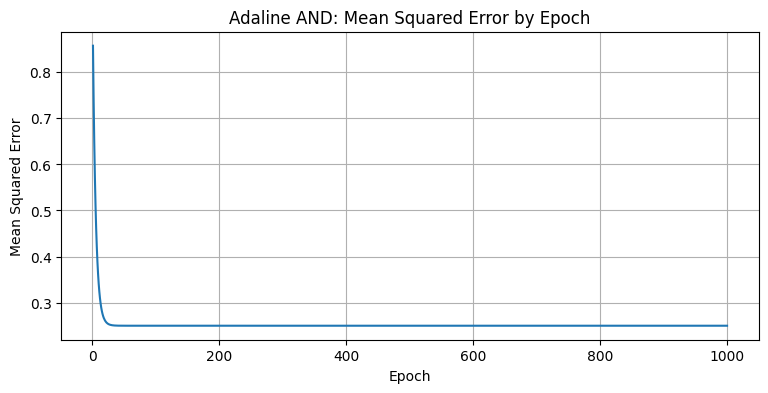

Initial MSE: 0.8575
Final MSE: 0.25
MSE decreased: True


In [21]:
plt.figure(figsize=(9, 4))
plt.plot(range(1, len(and_mse) + 1), and_mse)
plt.title("Adaline AND: Mean Squared Error by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.show()

print("Initial MSE:", round(and_mse[0], 6))
print("Final MSE:", round(and_mse[-1], 6))
print("MSE decreased:", and_mse[-1] < and_mse[0])

Cell 7 — Show the final AND result

In [22]:
and_results["Correct"] = and_results["Target"] == and_results["Prediction"]
display(and_results)

print("All predictions correct:", bool(and_results["Correct"].all()))
print("Adaline learns a linear decision boundary.")

,Input 1,Input 2,Target,Net Input,Prediction,Correct
0,-1,-1,-1,-1.5,-1,True
1,-1,1,-1,-0.5,-1,True
2,1,-1,-1,-0.5,-1,True
3,1,1,1,0.5,1,True


All predictions correct: True
Adaline learns a linear decision boundary.


##### Part B — Madaline-style network

Cell 8 — Create the bipolar XOR dataset

In [23]:
X_xor = np.array([
    [-1, -1],
    [-1, 1],
    [1, -1],
    [1, 1]
], dtype=float)

y_xor = np.array([-1, 1, 1, -1], dtype=float)

xor_table = pd.DataFrame(X_xor, columns=["Input 1", "Input 2"])
xor_table["Target"] = y_xor.astype(int)

display(xor_table)

print("Number of input patterns:", len(X_xor))
print("Bipolar targets:", y_xor.astype(int))

,Input 1,Input 2,Target
0,-1.0,-1.0,-1
1,-1.0,1.0,1
2,1.0,-1.0,1
3,1.0,1.0,-1


Number of input patterns: 4
Bipolar targets: [-1  1  1 -1]


Cell 9 — Visualize XOR

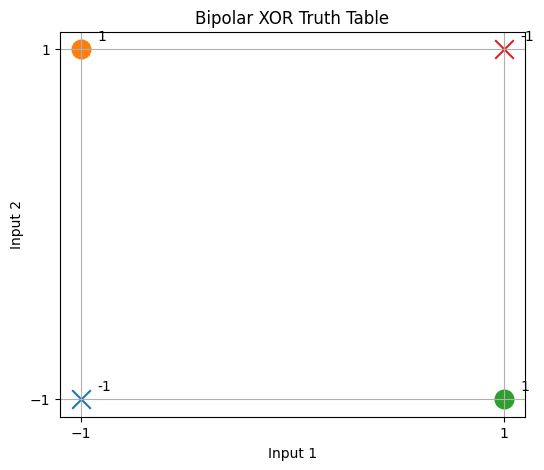

In [24]:
plt.figure(figsize=(6, 5))

for i, target in enumerate(y_xor):
    plt.scatter(
        X_xor[i, 0],
        X_xor[i, 1],
        s=180,
        marker="o" if target == 1 else "x"
    )
    plt.text(X_xor[i, 0] + 0.08, X_xor[i, 1] + 0.05, str(int(target)))

plt.title("Bipolar XOR Truth Table")
plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.xticks([-1, 1])
plt.yticks([-1, 1])
plt.grid(True)
plt.show()

Cell 10 — Train the hidden Adaline units and output unit

In [25]:
hidden_targets = np.array([
    [-1, 1, 1, 1],
    [1, 1, 1, -1]
], dtype=float)

hidden_weights = []
hidden_biases = []
hidden_mse = []

for targets in hidden_targets:
    weights, bias, mse = fit_adaline(
        X_xor, targets, learning_rate=0.1, epochs=1000
    )

    hidden_weights.append(weights)
    hidden_biases.append(bias)
    hidden_mse.append(mse)

hidden_weights = np.array(hidden_weights)
hidden_biases = np.array(hidden_biases)

hidden_net = X_xor @ hidden_weights.T + hidden_biases
hidden_output = bipolar_predict(hidden_net)

output_weights, output_bias, output_mse = fit_adaline(
    hidden_output, y_xor, learning_rate=0.1, epochs=1000
)

output_net = hidden_output @ output_weights + output_bias
xor_predictions = bipolar_predict(output_net)

print("Hidden layer weights:")
print(np.round(hidden_weights, 4))
print("\nHidden layer biases:")
print(np.round(hidden_biases, 4))
print("\nOutput layer weights:")
print(np.round(output_weights, 4))
print("Output layer bias:", round(output_bias, 4))

Hidden layer weights:
[[ 0.5  0.5]
 [-0.5 -0.5]]

Hidden layer biases:
[0.5 0.5]

Output layer weights:
[1. 1.]
Output layer bias: -1.0


Cell 11 — Display hidden-unit outputs and XOR predictions

In [26]:
madaline_results = pd.DataFrame({
    "Input 1": X_xor[:, 0].astype(int),
    "Input 2": X_xor[:, 1].astype(int),
    "Target": y_xor.astype(int),
    "Hidden Unit 1": hidden_output[:, 0],
    "Hidden Unit 2": hidden_output[:, 1],
    "Output Net": output_net,
    "Prediction": xor_predictions
})

madaline_results["Correct"] = (
    madaline_results["Target"] == madaline_results["Prediction"]
)

display(madaline_results.round(4))

print("XOR training accuracy:",
      round(np.mean(xor_predictions == y_xor) * 100, 2), "%")
print("All XOR predictions correct:",
      bool(madaline_results["Correct"].all()))

,Input 1,Input 2,Target,Hidden Unit 1,Hidden Unit 2,Output Net,Prediction,Correct
0,-1,-1,-1,-1,1,-1.0,-1,True
1,-1,1,1,1,1,1.0,1,True
2,1,-1,1,1,1,1.0,1,True
3,1,1,-1,1,-1,-1.0,-1,True


XOR training accuracy: 100.0 %
All XOR predictions correct: True


Cell 12 — Plot the training errors

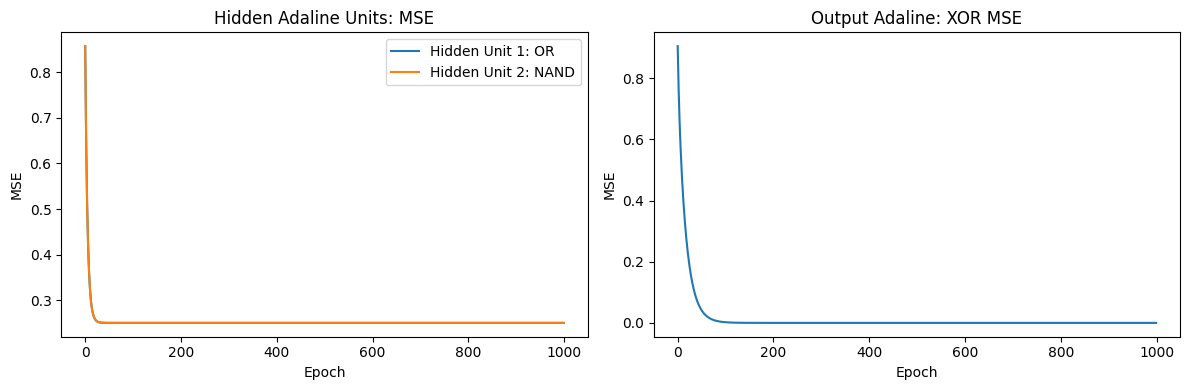

Hidden unit 1 final MSE: 0.25
Hidden unit 2 final MSE: 0.25
Output unit final MSE: 0.0


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hidden_mse[0], label="Hidden Unit 1: OR")
axes[0].plot(hidden_mse[1], label="Hidden Unit 2: NAND")
axes[0].set_title("Hidden Adaline Units: MSE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()

axes[1].plot(output_mse)
axes[1].set_title("Output Adaline: XOR MSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")

plt.tight_layout()
plt.show()

print("Hidden unit 1 final MSE:", round(hidden_mse[0][-1], 6))
print("Hidden unit 2 final MSE:", round(hidden_mse[1][-1], 6))
print("Output unit final MSE:", round(output_mse[-1], 6))

Cell 13 — Demonstrate why a single Adaline cannot solve XOR

In [28]:
single_weights, single_bias, single_mse = fit_adaline(
    X_xor, y_xor, learning_rate=0.1, epochs=1000
)

single_net = X_xor @ single_weights + single_bias
single_predictions = bipolar_predict(single_net)

comparison = pd.DataFrame({
    "Input 1": X_xor[:, 0].astype(int),
    "Input 2": X_xor[:, 1].astype(int),
    "Target": y_xor.astype(int),
    "Single Adaline": single_predictions,
    "Madaline-style Network": xor_predictions
})

comparison["Single Correct"] = (
    comparison["Target"] == comparison["Single Adaline"]
)

comparison["Madaline Correct"] = (
    comparison["Target"] == comparison["Madaline-style Network"]
)

display(comparison)

print("Single Adaline accuracy:",
      round(np.mean(single_predictions == y_xor) * 100, 2), "%")
print("Madaline-style accuracy:",
      round(np.mean(xor_predictions == y_xor) * 100, 2), "%")
print("Single Adaline final MSE:", round(single_mse[-1], 6))

,Input 1,Input 2,Target,Single Adaline,Madaline-style Network,Single Correct,Madaline Correct
0,-1,-1,-1,1,-1,False,True
1,-1,1,1,1,1,True,True
2,1,-1,1,1,1,True,True
3,1,1,-1,1,-1,False,True


Single Adaline accuracy: 50.0 %
Madaline-style accuracy: 100.0 %
Single Adaline final MSE: 1.0


Cell 14 — Final conclusion for Task 2

In [29]:
print("TASK 2 CONCLUSION")
print("\nPart A: Adaline")
print("Adaline uses a linear net input and the LMS rule to minimize mean squared error.")
print("The sign threshold converts the continuous output into a bipolar prediction.")
print("The AND experiment demonstrates learning a linearly separable classification problem.")

print("\nPart B: Madaline-style Network")
print("Two hidden Adaline units learn OR and NAND, and an output Adaline learns XOR.")
print("The hidden layer transforms the original inputs into a representation that makes XOR linearly separable.")
print("A single Adaline cannot correctly classify all XOR patterns because XOR is not linearly separable.")

print("\nAND accuracy:",
      round(np.mean(and_predictions == y_and) * 100, 2), "%")
print("Single Adaline XOR accuracy:",
      round(np.mean(single_predictions == y_xor) * 100, 2), "%")
print("Madaline-style XOR accuracy:",
      round(np.mean(xor_predictions == y_xor) * 100, 2), "%")

TASK 2 CONCLUSION

Part A: Adaline
Adaline uses a linear net input and the LMS rule to minimize mean squared error.
The sign threshold converts the continuous output into a bipolar prediction.
The AND experiment demonstrates learning a linearly separable classification problem.

Part B: Madaline-style Network
Two hidden Adaline units learn OR and NAND, and an output Adaline learns XOR.
The hidden layer transforms the original inputs into a representation that makes XOR linearly separable.
A single Adaline cannot correctly classify all XOR patterns because XOR is not linearly separable.

AND accuracy: 100.0 %
Single Adaline XOR accuracy: 50.0 %
Madaline-style XOR accuracy: 100.0 %


### Task 3 — Pattern Association and Associative Memory

Cell 1 — Import libraries

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Libraries imported successfully.")

NumPy version: 1.26.4
Libraries imported successfully.


Cell 2 — Create three input-output pairs

In [31]:
hetero_inputs = np.array([
    [1, -1, 1],
    [-1, 1, -1],
    [1, 1, -1]
])

hetero_outputs = np.array([
    [-1, 1],
    [1, 1],
    [-1, -1]
])

hetero_table = pd.DataFrame({
    "Input Pattern": [str(x.tolist()) for x in hetero_inputs],
    "Associated Output": [str(y.tolist()) for y in hetero_outputs]
})

display(hetero_table)

print("Number of stored pairs:", len(hetero_inputs))
print("Input pattern length:", hetero_inputs.shape[1])
print("Output pattern length:", hetero_outputs.shape[1])

,Input Pattern,Associated Output
0,"[1, -1, 1]","[-1, 1]"
1,"[-1, 1, -1]","[1, 1]"
2,"[1, 1, -1]","[-1, -1]"


Number of stored pairs: 3
Input pattern length: 3
Output pattern length: 2


Cell 3 — Visualize the stored patterns

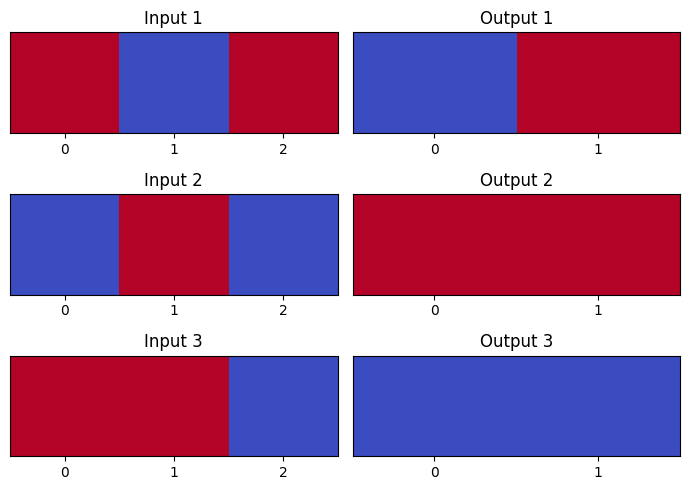

Red and blue shades represent bipolar values -1 and +1.


In [32]:
fig, axes = plt.subplots(3, 2, figsize=(7, 5))

for i in range(3):
    axes[i, 0].imshow(hetero_inputs[i].reshape(1, -1), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    axes[i, 0].set_title(f"Input {i + 1}")
    axes[i, 0].set_xticks(range(3))
    axes[i, 0].set_yticks([])

    axes[i, 1].imshow(hetero_outputs[i].reshape(1, -1), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    axes[i, 1].set_title(f"Output {i + 1}")
    axes[i, 1].set_xticks(range(2))
    axes[i, 1].set_yticks([])

plt.tight_layout()
plt.show()

print("Red and blue shades represent bipolar values -1 and +1.")

Cell 4 — Store the associations

In [33]:
hetero_memory = {
    tuple(input_pattern): output_pattern.copy()
    for input_pattern, output_pattern in zip(hetero_inputs, hetero_outputs)
}

print("Stored associations:", len(hetero_memory))

for input_pattern, output_pattern in hetero_memory.items():
    print(list(input_pattern), "->", output_pattern.tolist())

Stored associations: 3
[1, -1, 1] -> [-1, 1]
[-1, 1, -1] -> [1, 1]
[1, 1, -1] -> [-1, -1]


Cell 5 — Test recall for the stored inputs

In [45]:
hetero_results=[]

for i,x in enumerate(hetero_inputs):
    recalled=hetero_memory.get(tuple(x))
    expected=hetero_outputs[i]
    hetero_results.append({
        "Input Pattern":x.tolist(),
        "Expected Output":expected.tolist(),
        "Recalled Output":recalled.tolist() if recalled is not None else None,
        "Exact Match":recalled is not None and np.array_equal(recalled,expected)
    })

hetero_results_df=pd.DataFrame(hetero_results)
display(hetero_results_df)
print(f"Successful recalls: {hetero_results_df['Exact Match'].sum()}")
print(f"Total stored pairs: {len(hetero_results_df)}")
print(f"Exact recall accuracy: {hetero_results_df['Exact Match'].mean()*100:.1f}%")

,Input Pattern,Expected Output,Recalled Output,Exact Match
0,"[1, -1, 1]","[-1, 1]","[-1, 1]",True
1,"[-1, 1, -1]","[1, 1]","[1, 1]",True
2,"[1, 1, -1]","[-1, -1]","[-1, -1]",True


Successful recalls: 3
Total stored pairs: 3
Exact recall accuracy: 100.0%


Cell 6 — Test an unknown input

In [46]:
unknown_input = (-1, -1, -1)
unknown_output = hetero_memory.get(unknown_input)

print("Query input:", list(unknown_input))
print("Recalled output:", unknown_output)
print("Query found:", unknown_output is not None)

Query input: [-1, -1, -1]
Recalled output: None
Query found: False


Cell 7 — Create three bipolar patterns

In [47]:
auto_patterns = np.array([
    [1, 1, 1, -1, -1],
    [1, -1, -1, 1, -1],
    [-1, 1, -1, -1, 1]
])

auto_table = pd.DataFrame(
    auto_patterns,
    columns=[f"Bit {i + 1}" for i in range(auto_patterns.shape[1])]
)

auto_table.insert(0, "Pattern", [f"P{i + 1}" for i in range(len(auto_patterns))])

display(auto_table)

print("Number of stored patterns:", len(auto_patterns))
print("Pattern length:", auto_patterns.shape[1])
print("Unique patterns:", len(np.unique(auto_patterns, axis=0)))

,Pattern,Bit 1,Bit 2,Bit 3,Bit 4,Bit 5
0,P1,1,1,1,-1,-1
1,P2,1,-1,-1,1,-1
2,P3,-1,1,-1,-1,1


Number of stored patterns: 3
Pattern length: 5
Unique patterns: 3


Cell 8 — Visualize the patterns

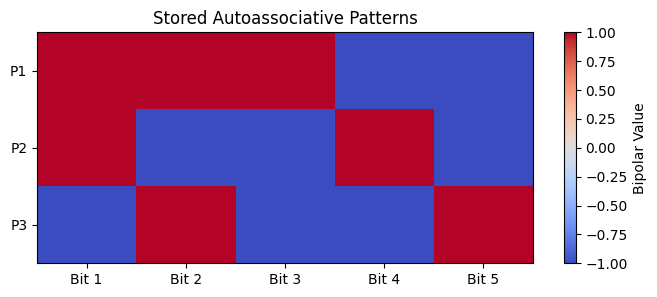

Each stored pattern should be recalled as itself.


In [48]:
plt.figure(figsize=(8, 3))

plt.imshow(auto_patterns, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(auto_patterns.shape[1]), [f"Bit {i + 1}" for i in range(auto_patterns.shape[1])])
plt.yticks(range(len(auto_patterns)), [f"P{i + 1}" for i in range(len(auto_patterns))])
plt.title("Stored Autoassociative Patterns")
plt.colorbar(label="Bipolar Value")
plt.show()

print("Each stored pattern should be recalled as itself.")

Cell 9 — Store patterns and define the recall rule

In [49]:
auto_memory = auto_patterns.copy()


def recall_pattern(query, memory):
    distances = np.sum(memory != query, axis=1)
    minimum_distance = distances.min()
    closest_indices = np.where(distances == minimum_distance)[0]

    if len(closest_indices) > 1:
        return None, int(minimum_distance), True

    return memory[closest_indices[0]].copy(), int(minimum_distance), False


print("Stored patterns:", len(auto_memory))
print("Recall rule: minimum Hamming distance")
print("Tie handling: report ambiguous recall")

Stored patterns: 3
Recall rule: minimum Hamming distance
Tie handling: report ambiguous recall


Cell 10 — Test recall from clean patterns

In [56]:
auto_clean_results=[]

for i,pattern in enumerate(auto_patterns):
    recalled,distance,tie=recall_pattern(pattern,auto_memory)
    auto_clean_results.append({
        "Stored Pattern":pattern.tolist(),
        "Query":pattern.tolist(),
        "Recalled Output":recalled.tolist() if recalled is not None else None,
        "Hamming Distance":distance,
        "Tie":tie,
        "Exact Match":recalled is not None and np.array_equal(recalled,pattern)
    })

auto_clean_df=pd.DataFrame(auto_clean_results)
display(auto_clean_df)
print(f"Clean recall accuracy: {auto_clean_df['Exact Match'].mean()*100:.1f}%")

,Stored Pattern,Query,Recalled Output,Hamming Distance,Tie,Exact Match
0,"[1, 1, 1, -1, -1]","[1, 1, 1, -1, -1]","[1, 1, 1, -1, -1]",0,False,True
1,"[1, -1, -1, 1, -1]","[1, -1, -1, 1, -1]","[1, -1, -1, 1, -1]",0,False,True
2,"[-1, 1, -1, -1, 1]","[-1, 1, -1, -1, 1]","[-1, 1, -1, -1, 1]",0,False,True


Clean recall accuracy: 100.0%


Cell 11 — Test recall from corrupted patterns

In [57]:
corrupted_patterns = auto_patterns.copy()
corrupted_patterns[0, 0] *= -1
corrupted_patterns[1, 1] *= -1
corrupted_patterns[2, 4] *= -1

corrupted_results = []

for i, (original, query) in enumerate(zip(auto_patterns, corrupted_patterns)):
    recalled, distance, tie = recall_pattern(query, auto_memory)

    corrupted_results.append({
        "Stored Pattern": f"P{i + 1}",
        "Corrupted Query": query.tolist(),
        "Bits Flipped": int(np.sum(original != query)),
        "Recalled Output": recalled.tolist() if recalled is not None else None,
        "Hamming Distance": distance,
        "Tie": tie,
        "Exact Match": bool(recalled is not None and np.array_equal(recalled, original))
    })

corrupted_results_df = pd.DataFrame(corrupted_results)
display(corrupted_results_df)

print("Corrupted recall accuracy:",
      round(corrupted_results_df["Exact Match"].mean() * 100, 2), "%")

,Stored Pattern,Corrupted Query,Bits Flipped,Recalled Output,Hamming Distance,Tie,Exact Match
0,P1,"[-1, 1, 1, -1, -1]",1,"[1, 1, 1, -1, -1]",1,False,True
1,P2,"[1, 1, -1, 1, -1]",1,"[1, -1, -1, 1, -1]",1,False,True
2,P3,"[-1, 1, -1, -1, -1]",1,"[-1, 1, -1, -1, 1]",1,False,True


Corrupted recall accuracy: 100.0 %


Cell 12 — Visualize clean and corrupted recall

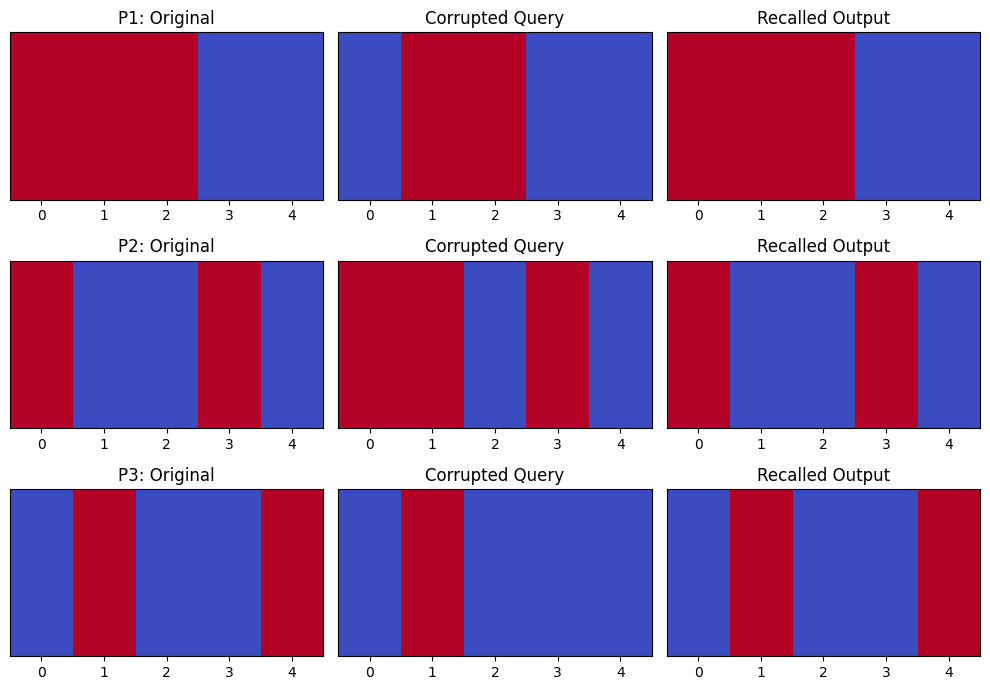

Compare each original, corrupted, and recalled pattern.


In [58]:
fig, axes = plt.subplots(3, 3, figsize=(10, 7))

for i in range(3):
    recalled, _, _ = recall_pattern(corrupted_patterns[i], auto_memory)

    axes[i, 0].imshow(auto_patterns[i].reshape(1, -1), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    axes[i, 0].set_title(f"P{i + 1}: Original")

    axes[i, 1].imshow(corrupted_patterns[i].reshape(1, -1), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    axes[i, 1].set_title("Corrupted Query")

    if recalled is not None:
        axes[i, 2].imshow(recalled.reshape(1, -1), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    else:
        axes[i, 2].text(0.5, 0.5, "Ambiguous", ha="center", va="center")

    axes[i, 2].set_title("Recalled Output")

    for j in range(3):
        axes[i, j].set_xticks(range(5))
        axes[i, j].set_yticks([])

plt.tight_layout()
plt.show()

print("Compare each original, corrupted, and recalled pattern.")

Cell 13 — Summarize all recall experiments

In [62]:
summary_results=[]

for i,x in enumerate(hetero_inputs):
    recalled=hetero_memory.get(tuple(x))
    summary_results.append({
        "Memory Type":"Heteroassociative",
        "Stored Pattern":x.tolist(),
        "Query / Noise":"Clean input",
        "Recalled Output":recalled.tolist() if recalled is not None else None,
        "Exact Match":recalled is not None and np.array_equal(recalled,hetero_outputs[i])
    })

for i,pattern in enumerate(auto_patterns):
    recalled,distance,tie=recall_pattern(pattern,auto_memory)
    summary_results.append({
        "Memory Type":"Autoassociative",
        "Stored Pattern":pattern.tolist(),
        "Query / Noise":"Clean input",
        "Recalled Output":recalled.tolist() if recalled is not None else None,
        "Exact Match":recalled is not None and np.array_equal(recalled,pattern)
    })

for i,query in enumerate(corrupted_patterns):
    recalled,distance,tie=recall_pattern(query,auto_memory)
    summary_results.append({
        "Memory Type":"Autoassociative",
        "Stored Pattern":auto_patterns[i].tolist(),
        "Query / Noise":f"One bit flipped: {query.tolist()}",
        "Recalled Output":recalled.tolist() if recalled is not None else None,
        "Exact Match":recalled is not None and np.array_equal(recalled,auto_patterns[i])
    })

summary_df=pd.DataFrame(summary_results)
display(summary_df)
print(f"Total recall tests: {len(summary_df)}")
print(f"Successful exact matches: {summary_df['Exact Match'].sum()}")
print(f"Overall exact-match rate: {summary_df['Exact Match'].mean()*100:.1f}%")

,Memory Type,Stored Pattern,Query / Noise,Recalled Output,Exact Match
0,Heteroassociative,"[1, -1, 1]",Clean input,"[-1, 1]",True
1,Heteroassociative,"[-1, 1, -1]",Clean input,"[1, 1]",True
2,Heteroassociative,"[1, 1, -1]",Clean input,"[-1, -1]",True
3,Autoassociative,"[1, 1, 1, -1, -1]",Clean input,"[1, 1, 1, -1, -1]",True
4,Autoassociative,"[1, -1, -1, 1, -1]",Clean input,"[1, -1, -1, 1, -1]",True
5,Autoassociative,"[-1, 1, -1, -1, 1]",Clean input,"[-1, 1, -1, -1, 1]",True
6,Autoassociative,"[1, 1, 1, -1, -1]","One bit flipped: [-1, 1, 1, -1, -1]","[1, 1, 1, -1, -1]",True
7,Autoassociative,"[1, -1, -1, 1, -1]","One bit flipped: [1, 1, -1, 1, -1]","[1, -1, -1, 1, -1]",True
8,Autoassociative,"[-1, 1, -1, -1, 1]","One bit flipped: [-1, 1, -1, -1, -1]","[-1, 1, -1, -1, 1]",True


Total recall tests: 9
Successful exact matches: 9
Overall exact-match rate: 100.0%


Cell 14 — Demonstrate a limitation

In [63]:
unknown_input=np.array([-1,-1,-1])
unknown_output=hetero_memory.get(tuple(unknown_input))

unknown_df=pd.DataFrame([{
    "Query Input":unknown_input.tolist(),
    "Query Found":unknown_output is not None,
    "Recalled Output":unknown_output.tolist() if unknown_output is not None else None,
    "Exact Match":False
}])

display(unknown_df)
print("Limitation: lookup-based heteroassociative memory only recalls exact stored inputs.")
print("An unknown input has no associated output unless an additional rule is defined.")

,Query Input,Query Found,Recalled Output,Exact Match
0,"[-1, -1, -1]",False,None,False


Limitation: lookup-based heteroassociative memory only recalls exact stored inputs.
An unknown input has no associated output unless an additional rule is defined.


Cell 15 — Final conclusion for Task 3

In [64]:
print("TASK 3 CONCLUSION")

print("\nHeteroassociative Memory")
print("Stores associations between different input and output patterns.")
print("All stored input-output pairs were recalled using exact lookup.")

print("\nAutoassociative Memory")
print("Stores patterns and recalls the closest stored pattern.")
print("Nearest-pattern recall was tested using clean patterns and one-bit corrupted patterns.")

print("\nLimitation")
print("Lookup-based heteroassociative memory cannot generalize to unseen inputs.")
print("Nearest-pattern autoassociative recall can fail when a query is ambiguous or too far from stored patterns.")

print("\nHeteroassociative exact recall:",
      round(hetero_results_df["Exact Match"].mean() * 100, 2), "%")
print("Autoassociative clean recall:",
      round(clean_results_df["Exact Match"].mean() * 100, 2), "%")
print("Autoassociative corrupted recall:",
      round(corrupted_results_df["Exact Match"].mean() * 100, 2), "%")

TASK 3 CONCLUSION

Heteroassociative Memory
Stores associations between different input and output patterns.
All stored input-output pairs were recalled using exact lookup.

Autoassociative Memory
Stores patterns and recalls the closest stored pattern.
Nearest-pattern recall was tested using clean patterns and one-bit corrupted patterns.

Limitation
Lookup-based heteroassociative memory cannot generalize to unseen inputs.
Nearest-pattern autoassociative recall can fail when a query is ambiguous or too far from stored patterns.

Heteroassociative exact recall: 100.0 %
Autoassociative clean recall: 100.0 %
Autoassociative corrupted recall: 100.0 %


### Task 4 — Hopfield Network

Cell 1 — Imports and define patterns

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

patterns=np.array([
    [1,1,1,1,-1,-1,-1,-1],
    [1,1,-1,-1,1,1,-1,-1],
    [1,-1,1,-1,1,-1,1,-1]
])

print("Number of patterns:",len(patterns))
print("Pattern length:",patterns.shape[1])
print("Unique patterns:",len(np.unique(patterns,axis=0)))

patterns_df=pd.DataFrame(
    patterns,
    index=[f"P{i+1}" for i in range(len(patterns))],
    columns=[f"Bit {i+1}" for i in range(patterns.shape[1])]
)

display(patterns_df)

Number of patterns: 3
Pattern length: 8
Unique patterns: 3


,Bit 1,Bit 2,Bit 3,Bit 4,Bit 5,Bit 6,Bit 7,Bit 8
P1,1,1,1,1,-1,-1,-1,-1
P2,1,1,-1,-1,1,1,-1,-1
P3,1,-1,1,-1,1,-1,1,-1


Cell 2 — Calculate the Hebbian weight matrix

In [66]:
N=patterns.shape[1]
weights=patterns.T@patterns/N
np.fill_diagonal(weights,0)

weights_df=pd.DataFrame(
    weights,
    index=[f"N{i+1}" for i in range(N)],
    columns=[f"N{i+1}" for i in range(N)]
)

print("Hopfield Weight Matrix")
display(weights_df)
print("Diagonal weights are all zero:",np.all(np.diag(weights)==0))
print("Weight matrix is symmetric:",np.allclose(weights,weights.T))

Hopfield Weight Matrix


,N1,N2,N3,N4,N5,N6,N7,N8
N1,0.000,0.125,0.125,-0.125,0.125,-0.125,-0.125,-0.375
N2,0.125,0.000,-0.125,0.125,-0.125,0.125,-0.375,-0.125
N3,0.125,-0.125,0.000,0.125,-0.125,-0.375,0.125,-0.125
N4,-0.125,0.125,0.125,0.000,-0.375,-0.125,-0.125,0.125
N5,0.125,-0.125,-0.125,-0.375,0.000,0.125,0.125,-0.125
N6,-0.125,0.125,-0.375,-0.125,0.125,0.000,-0.125,0.125
N7,-0.125,-0.375,0.125,-0.125,0.125,-0.125,0.000,0.125
N8,-0.375,-0.125,-0.125,0.125,-0.125,0.125,0.125,0.000


Diagonal weights are all zero: True
Weight matrix is symmetric: True


Cell 3 — Energy function and recall algorithm

In [67]:
def hopfield_energy(state,weights):
    return -0.5*state@weights@state

def hopfield_recall(query,weights,max_updates=100):
    state=np.array(query,dtype=int).copy()
    energy_history=[hopfield_energy(state,weights)]
    updates=0
    stable=False

    while updates<max_updates:
        changed=False

        for i in range(len(state)):
            if updates>=max_updates:
                break

            net_input=weights[i]@state

            if net_input>0:
                new_state=1
            elif net_input<0:
                new_state=-1
            else:
                new_state=state[i]

            if new_state!=state[i]:
                state[i]=new_state
                changed=True

            energy_history.append(hopfield_energy(state,weights))
            updates+=1

        if not changed:
            stable=True
            break

    return state,energy_history,stable,updates

print("Asynchronous recall function created.")
print("Tie rule: retain the current neuron state.")
print("Maximum updates:",100)

Asynchronous recall function created.
Tie rule: retain the current neuron state.
Maximum updates: 100


Cell 4 — Recall all clean patterns

In [68]:
clean_results=[]

for i,pattern in enumerate(patterns):
    recalled,energy_history,stable,updates=hopfield_recall(pattern,weights)

    clean_results.append({
        "Stored Pattern":f"P{i+1}",
        "Input":pattern.tolist(),
        "Recalled Output":recalled.tolist(),
        "Stable":stable,
        "Updates":updates,
        "Exact Match":np.array_equal(recalled,pattern)
    })

clean_df=pd.DataFrame(clean_results)
display(clean_df)

clean_accuracy=clean_df["Exact Match"].mean()*100
print(f"Clean recall accuracy: {clean_accuracy:.1f}%")

,Stored Pattern,Input,Recalled Output,Stable,Updates,Exact Match
0,P1,"[1, 1, 1, 1, -1, -1, -1, -1]","[1, 1, 1, 1, -1, -1, -1, -1]",True,8,True
1,P2,"[1, 1, -1, -1, 1, 1, -1, -1]","[1, 1, -1, -1, 1, 1, -1, -1]",True,8,True
2,P3,"[1, -1, 1, -1, 1, -1, 1, -1]","[1, -1, 1, -1, 1, -1, 1, -1]",True,8,True


Clean recall accuracy: 100.0%


Cell 5 — Recall with different numbers of flipped bits

In [74]:
rng=np.random.default_rng(42)
corrupted_results=[]
energy_query=None
energy_original=None

for i,pattern in enumerate(patterns):
    for bits_flipped in [1,2,3]:
        flip_indices=rng.choice(N,size=bits_flipped,replace=False)
        query=pattern.copy()
        query[flip_indices]*=-1

        recalled,energy_history,stable,updates=hopfield_recall(query,weights)

        corrupted_results.append({
            "Stored Pattern":f"P{i+1}",
            "Bits Flipped":bits_flipped,
            "Flipped Positions":[int(j+1) for j in sorted(flip_indices)],
            "Corrupted Query":query.tolist(),
            "Recalled Output":recalled.tolist(),
            "Hamming Distance":int(np.sum(recalled!=pattern)),
            "Stable":stable,
            "Exact Match":bool(np.array_equal(recalled,pattern))
        })

        if i==0 and bits_flipped==2:
            energy_query=query.copy()
            energy_original=pattern.copy()
            energy_history_sample=energy_history.copy()
            energy_recalled=recalled.copy()

corrupted_df=pd.DataFrame(corrupted_results)
display(corrupted_df)

corrupted_accuracy=corrupted_df["Exact Match"].mean()*100
print(f"Corrupted recall success rate: {corrupted_accuracy:.1f}%")
print(f"Successful recalls: {corrupted_df['Exact Match'].sum()} out of {len(corrupted_df)}")

,Stored Pattern,Bits Flipped,Flipped Positions,Corrupted Query,Recalled Output,Hamming Distance,Stable,Exact Match
0,P1,1,[1],"[-1, 1, 1, 1, -1, -1, -1, -1]","[1, 1, 1, 1, -1, -1, -1, -1]",0,True,True
1,P1,2,"[6, 8]","[1, 1, 1, 1, -1, 1, -1, 1]","[-1, 1, -1, 1, -1, 1, -1, 1]",4,True,False
2,P1,3,"[1, 3, 7]","[-1, 1, -1, 1, -1, -1, 1, -1]","[1, 1, 1, 1, -1, -1, -1, -1]",0,True,True
3,P2,1,[1],"[-1, 1, -1, -1, 1, 1, -1, -1]","[1, 1, -1, -1, 1, 1, -1, -1]",0,True,True
4,P2,2,"[4, 8]","[1, 1, -1, 1, 1, 1, -1, 1]","[-1, 1, -1, -1, 1, 1, -1, 1]",2,True,False
5,P2,3,"[5, 6, 7]","[1, 1, -1, -1, -1, -1, 1, -1]","[1, -1, 1, 1, -1, -1, 1, -1]",6,True,False
6,P3,1,[7],"[1, -1, 1, -1, 1, -1, -1, -1]","[1, 1, 1, -1, 1, -1, -1, -1]",2,True,False
7,P3,2,"[4, 5]","[1, -1, 1, 1, -1, -1, 1, -1]","[1, -1, 1, 1, -1, -1, 1, -1]",2,True,False
8,P3,3,"[2, 7, 8]","[1, 1, 1, -1, 1, -1, -1, 1]","[1, -1, 1, -1, 1, -1, 1, -1]",0,True,True


Corrupted recall success rate: 44.4%
Successful recalls: 4 out of 9


Cell 6 — Plot original, corrupted, and recalled patterns

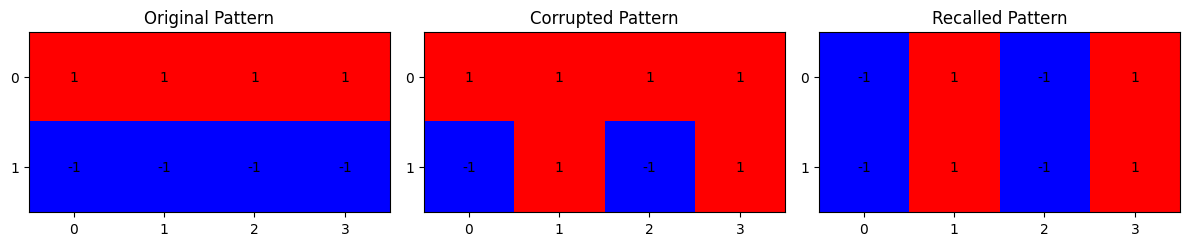

Original: [1, 1, 1, 1, -1, -1, -1, -1]
Corrupted: [1, 1, 1, 1, -1, 1, -1, 1]
Recalled: [-1, 1, -1, 1, -1, 1, -1, 1]
Exact match: False


In [75]:
fig,axes=plt.subplots(1,3,figsize=(12,3))

plot_patterns=[
    (energy_original,"Original Pattern"),
    (energy_query,"Corrupted Pattern"),
    (energy_recalled,"Recalled Pattern")
]

for ax,(pattern,title) in zip(axes,plot_patterns):
    ax.imshow(pattern.reshape(2,4),cmap="bwr",vmin=-1,vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(4))
    ax.set_yticks(range(2))

    for r in range(2):
        for c in range(4):
            ax.text(c,r,str(pattern.reshape(2,4)[r,c]),ha="center",va="center")

plt.tight_layout()
plt.show()

print("Original:",energy_original.tolist())
print("Corrupted:",energy_query.tolist())
print("Recalled:",energy_recalled.tolist())
print("Exact match:",np.array_equal(energy_original,energy_recalled))

Cell 7 — Energy during asynchronous updates

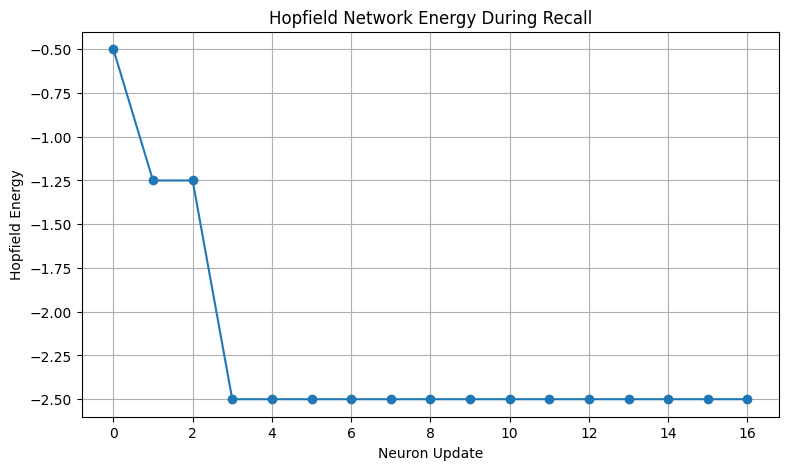

Initial energy: -0.5
Final energy: -2.5
Energy decreased or stayed constant: True


In [76]:
plt.figure(figsize=(9,5))
plt.plot(range(len(energy_history_sample)),energy_history_sample,marker="o")
plt.xlabel("Neuron Update")
plt.ylabel("Hopfield Energy")
plt.title("Hopfield Network Energy During Recall")
plt.grid(True)
plt.show()

print("Initial energy:",round(energy_history_sample[0],4))
print("Final energy:",round(energy_history_sample[-1],4))
print("Energy decreased or stayed constant:",all(
    energy_history_sample[i+1]<=energy_history_sample[i]+1e-9
    for i in range(len(energy_history_sample)-1)
))

Cell 8 — Show the energy values in a table

In [77]:
energy_df=pd.DataFrame({
    "Update":range(len(energy_history_sample)),
    "Energy":energy_history_sample
})

display(energy_df.round(4))

,Update,Energy
0,0,-0.50
1,1,-1.25
2,2,-1.25
3,3,-2.50
4,4,-2.50
5,5,-2.50
6,6,-2.50
7,7,-2.50
8,8,-2.50
9,9,-2.50


Cell 9 — Summary of recall performance

In [78]:
results_summary=pd.DataFrame([
    {
        "Test":"Clean patterns",
        "Successful":int(clean_df["Exact Match"].sum()),
        "Total":len(clean_df),
        "Success Rate (%)":clean_accuracy
    },
    {
        "Test":"Corrupted patterns",
        "Successful":int(corrupted_df["Exact Match"].sum()),
        "Total":len(corrupted_df),
        "Success Rate (%)":corrupted_accuracy
    }
])

display(results_summary.round(2))

print("TASK 4 CONCLUSION")
print("1. Hebbian learning stored three bipolar patterns in a symmetric weight matrix.")
print("2. The diagonal weights were set to zero.")
print("3. Asynchronous recall updated one neuron at a time.")
print("4. A neuron with zero weighted input retained its current state.")
print("5. Energy was tracked during recall.")
print("6. Energy did not increase during asynchronous updates.")
print("7. A stable state is not always the original pattern.")
print(f"Clean recall success rate: {clean_accuracy:.1f}%")
print(f"Corrupted recall success rate: {corrupted_accuracy:.1f}%")

,Test,Successful,Total,Success Rate (%)
0,Clean patterns,3,3,100.00
1,Corrupted patterns,4,9,44.44


TASK 4 CONCLUSION
1. Hebbian learning stored three bipolar patterns in a symmetric weight matrix.
2. The diagonal weights were set to zero.
3. Asynchronous recall updated one neuron at a time.
4. A neuron with zero weighted input retained its current state.
5. Energy was tracked during recall.
6. Energy did not increase during asynchronous updates.
7. A stable state is not always the original pattern.
Clean recall success rate: 100.0%
Corrupted recall success rate: 44.4%
